# A buried film from real neutron reflections


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `neutron_reflectometry_thin_film` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：q (1, 408) float64：Momentum transfer Q, Angstrom^-1; axes (batch, observation).；reflectivity (1, 408) float64：Measured specular intensity ratio, dimensionless; axes (batch, observation).；standard_error (1, 408) float64：One standard deviation reflectivity uncertainty, dimensionless; axes (batch, observation).；q_fwhm (1, 408) float64：Point dependent Gaussian Q resolution FWHM, Angstrom^-1; axes (batch, observation).。恢复目标：821点深度SLD及八个薄膜结构/强度参数，10^-6 Angstrom^-2等。

获取模型：分层Abeles/Fresnel复reflection振幅平方，经Gaussian Q分辨率积分加background。实际恢复算法：solvers.reconstruct以differential_evolution优化weighted likelihood；physics_model.profile生成SLD。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:5无独立显微结构真值；baseline为原始方法SLD与参数。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：neutron_reflectometry_thin_film.ipynb单元0：5. Results；neutron_reflectometry_thin_film.ipynb单元3：Scientific comparison；neutron_reflectometry_thin_film.ipynb单元4有保存图；图内容由该单元调用的本地visualization函数生成。图/比较代码位于单元4（从0计数）。代码单元4个，带execution_count的4个，保存PNG输出1幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem


This review actively reconstructs every one of the 408 PLATYPUS observations using only the cleaned local NumPy/SciPy implementation. The result is compared with an independently executed, exact revision upstream maximum likelihood fit. Neither is labeled microscopic ground truth.

Specular reflection loses phase; the measured fringes encode depth through interference but do not uniquely determine a freeform profile. We therefore use the selected published/tutorial four medium model: silicon, native oxide, uniform film, heavy water. This notebook selects its deterministic maximum likelihood stage. The tutorial's unrelated straight line and synthetic multilayer examples, and optional MCMC posterior experiment, are outside this benchmark; no missing posterior samples are represented as newly computed results.

## 2. Data

`data/raw_data.npz` contains all 408 measured points, in their original precision and ordering.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| q | (1, 408) | float64 | Momentum transfer Q, Angstrom^-1; axes (batch, observation). |
| reflectivity | (1, 408) | float64 | Measured specular intensity ratio, dimensionless; axes (batch, observation). |
| standard_error | (1, 408) | float64 | One standard deviation reflectivity uncertainty, dimensionless; axes (batch, observation). |
| q_fwhm | (1, 408) | float64 | Point dependent Gaussian Q resolution FWHM, Angstrom^-1; axes (batch, observation). |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Instrument | PLATYPUS | — | Neutron reflectometer; supplied curve is already reduced to specular reflectivity. |
| Fronting SLD | 2.07 | 10^-6 Angstrom^-2 | Semi-infinite silicon incident medium. |
| Oxide SLD | 3.47 | 10^-6 Angstrom^-2 | Fixed uniform native oxide layer SLD. |
| Backing SLD | 6.36 | 10^-6 Angstrom^-2 | Semi-infinite heavy water exit medium. |
| Imaginary SLD | 0 | Angstrom^-2 | Absorption neglected for all four media. |
| Depth origin | 0 | Angstrom | Silicon/native oxide interface. |
| Positive depth | silicon toward water | — | Layer order: silicon, oxide, film, water. |
| Lateral convention | uniform layers | — | Specular approximation, laterally averaged structure. |
| Interface convention | Nevot–Croce | — | Gaussian roughness damping of interface amplitudes. |
| Resolution model | Gaussian, per observation FWHM | Angstrom^-1 | Widths supplied by q_fwhm; sigma = FWHM/(2 sqrt(2 ln(2))). |
| Boundary convention | semi-infinite fronting and backing | — | No second reflection beyond bounding media. |
| Noise information | supplied standard errors | dimensionless | Independent point uncertainty approximation; residual systematics may remain. |

The supplied Q values and widths are sufficient to formulate the reduced measurement model; unreleased wavelength or detector geometry is not required. No extra calibration observations are assumed.

## 3. Physics

### Physics and objective

For momentum transfer $Q=4\pi\sin\theta/\lambda$, grazing angle $\theta$ and wavelength $\lambda$, the normal wavevector in medium $j$ is $k_j=\sqrt{Q^2/4-4\pi(\rho_j-\rho_0)}$. Here $\rho_j$ is nuclear scattering length density (SLD) in inverse square angstroms and $\rho_0$ is incident silicon SLD. The interface coefficient between adjacent media is


$$
r_j=\frac{k_j-k_{j+1}}{k_j+k_{j+1}}\exp(-2k_jk_{j+1}\sigma_{j+1}^2),
$$


where $\sigma$ is Gaussian interface roughness. Multiplying the explicit interface and propagation matrices (finite layer phase $\exp(ik_j d_j)$ for thickness $d_j$) yields amplitude $a(Q)$. Its intensity is $|a|^2$. We convolve intensity with a Gaussian instrument response for each supplied Q width, then apply scale $s$ and background $b$. The exact upstream approximation uses 17 Gauss–Legendre nodes over ±3.5 instrument standard deviations without truncation renormalization.

For measured intensities $R_i$, standard deviations $e_i$, and predicted intensities $P_i$, let $y_i=\log_{10}R_i$, $m_i=\log_{10}P_i$, and $t_i=e_i/(R_i\ln10)$. Minimize


$$
L=\tfrac12\sum_i[(y_i-m_i)^2/t_i^2+\ln(2\pi t_i^2)].
$$


All eight physical/nuisance unknowns vary within the validated tutorial bounds. There is no learned prior or regularizer. Single worker differential evolution (seed 2718, population multiplier 15, tolerance $10^{-8}$, up to 1000 generations) and default bounded polishing implement the same fitting stage. The depth profile is the sum of error function SLD jumps at depths 0, oxide thickness, and total finite thickness; z increases into the water.

## 4. Method

Evaluate the ordered multilayer characteristic matrices and the 17-node truncated Gaussian resolution integral at all 408 observed $Q$. Fit eight bounded parameters (scale, background, oxide thickness/roughness, film thickness/SLD and remaining roughnesses) by single-worker differential evolution plus bounded polishing. In the log-intensity likelihood, $t_i=e_i/(R_i\ln10)$ is the propagated observational standard deviation and

$$
L=\tfrac12\sum_i[(\log_{10}R_i-\log_{10}P_i)^2/t_i^2+\log(2\pi t_i^2)].
$$

$R_i,e_i$ are observed reflectivity/error and $P_i$ the forward prediction. The reconstructed error-function SLD profile is a consequence of this slab/roughness model, not a freeform independently measured depth image.

## 5. Results




In [1]:
from pathlib import Path
import sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations
from src.physics_model import Z,INITIAL,BOUNDS,forward,negative_log_likelihood,residuals
from src.solvers import reconstruct
from src.visualization import comparisons
data=load_observations()
print('Complete real observations:',len(data[0]))
print('Q range (Angstrom^-1):',float(data[0].min()),float(data[0].max()))
print('NumPy:',np.__version__)


Complete real observations: 408
Q range (Angstrom^-1): 0.00806022 0.465555
NumPy: 2.4.6


In [2]:
start=time.perf_counter()
fresh,info=reconstruct(*data)
print('ACTIVELY COMPUTED fresh inversion:',json.dumps(info,indent=2))
np.savez(ROOT/'output/reconstruction.npz',**fresh)
with np.load(ROOT/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as a:
    upstream={k:a[k].copy() for k in a.files}
print('Fresh weighted log chi squared:',float(np.sum(residuals(fresh['parameters'][0],*data)**2)))
print('Initial weighted log chi squared:',float(np.sum(residuals(INITIAL,*data)**2)))


ACTIVELY COMPUTED fresh inversion: {
  "seconds": 31.88151440001093,
  "nll": -571.1242081121126,
  "iterations": 147,
  "optimizer_success": true,
  "optimizer_message": "Optimization terminated successfully."
}
Fresh weighted log chi squared: 919.5863753459407
Initial weighted log chi squared: 34376.6909230514


### Scientific comparison

The measured curve, the actual initialization, the independently reproduced upstream fit, and this notebook's fresh fit are all shown. The SLD panel compares method reconstructions, not truth. The weighted residual panel retains visible model mismatch rather than replacing the measured curve with a synthetic fit.


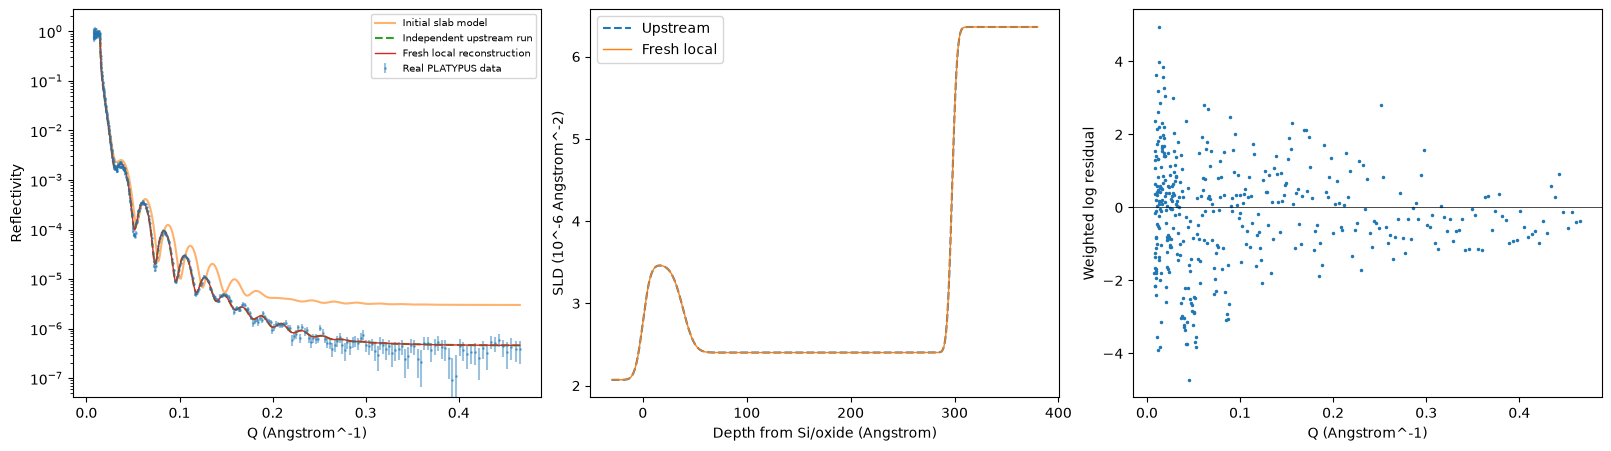

Parameter                 Unit                        Initial   Upstream run    Fresh local
scale                     1                                 1      0.8793943      0.8793943
background                1                             3e-06   4.587419e-07   4.587419e-07
oxide thickness           Angstrom                         30       38.64006       38.64006
Si/oxide roughness        Angstrom                          3       5.843395       5.843395
film thickness            Angstrom                        250       259.0399       259.0399
film SLD                  1e-6 Angstrom^-2                  2       2.402012       2.402012
oxide/film roughness      Angstrom                          3       8.824293       8.824293
film/water roughness      Angstrom                          3       3.787881       3.787881


In [3]:
fig=comparisons(data,fresh,upstream)
fig.savefig(ROOT/'output/review.png',dpi=150)
plt.show()
names=['scale','background','oxide thickness','Si/oxide roughness','film thickness','film SLD','oxide/film roughness','film/water roughness']
units=['1','1','Angstrom','Angstrom','Angstrom','1e-6 Angstrom^-2','Angstrom','Angstrom']
print(f"{'Parameter':25s} {'Unit':20s} {'Initial':>14s} {'Upstream run':>14s} {'Fresh local':>14s}")
for name,unit,ini,u,v in zip(names,units,INITIAL,upstream['parameters'][0],fresh['parameters'][0]):
    print(f'{name:25s} {unit:20s} {ini:14.7g} {u:14.7g} {v:14.7g}')


### Evaluation and interpretation

The standalone evaluator checks float64 shapes/finiteness, both required arrays, profile RMS error normalized by upstream profile dynamic range, maximum range normalized parameter error, and log intensity forward consistency. There is no rescaling or depth alignment. Boundaries were fixed from two independent upstream fits before comparing the cleaned output: profile NRMSE 2e-5, parameter error 2e-4, chi squared 930. The upstream fits differed by profile NRMSE 2.1706143e-6. These numerical criteria measure agreement with this selected physical model, not independent microscopic accuracy.


In [4]:
spec=importlib.util.spec_from_file_location('judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,code=judge.evaluate(ROOT/'output/reconstruction.npz')
print(json.dumps(report,indent=2))
assert code==0
chi=report['metrics']['log_chisqr']
print('Reduced log chi squared (408-8 degrees of freedom):',chi/400)
print('Notebook active reconstruction wall time (s):',info['seconds'])


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "profile_nrmse": 5.368655598089066e-11,
    "parameter_error": 4.495999868699604e-10,
    "log_chisqr": 919.5863753459407
  },
  "thresholds": {
    "profile_nrmse": {
      "comparison": "<=",
      "boundary": 2e-05
    },
    "parameter_error": {
      "comparison": "<=",
      "boundary": 0.0002
    },
    "log_chisqr": {
      "comparison": "<=",
      "boundary": 930.0
    }
  },
  "errors": []
}
Reduced log chi squared (408-8 degrees of freedom): 2.298965938364852
Notebook active reconstruction wall time (s): 31.88151440001093


## 6. Conclusion


The fresh local reconstruction agrees with the independently executed upstream inversion and explains the observed interference structure using explicit multilayer wave physics. The film thickness, SLD and interface roughness are model parameters inferred from the measured intensity curve. Reduced log chi squared is approximately 2.30, so residual systematics and the simple layer/noise approximation remain scientifically relevant. Reference agreement cannot establish a unique true depth profile. Historical paper illustrations are not numerical evidence for this observation; all reported comparison values above are measured by this task's independent oracle or this notebook's active computation.
